# Improving the Employability of IT Students
## Research Results, Data Analysis, and Scientific Visualization

This notebook walks through the full analysis: **ingestion and filtering → statistical aggregation → visualization and export**. All calculations are implemented in `src/` (`process_data.py`, `statistical_analysis.py`, `visualize.py`); the notebook imports them, so the notebook, the scripts and the committed outputs always agree.

**Data limitation.** The dataset contains eight *synthetic* demonstration records. The results test the pipeline; they are not evidence about the student population, and the hypotheses H1–H3 cannot be tested with them.

**Reproducibility.** Run the notebook with *Kernel → Restart & Run All*. Every random step uses seed `42`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

# Project root is the parent of the notebooks/ directory.
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src import process_data, statistical_analysis, visualize

# Fixed randomness: bootstrap and jitter use this seed everywhere.
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("Project root folder:", PROJECT_ROOT.name)
print("Random seed:", RANDOM_SEED)

Project root folder: work
Random seed: 42


## 1. Data ingestion and filtering

The raw file `data/sample/sample.csv` contains per-student survey-style counts, not timed benchmark runs. There is therefore **no warm-up phase to discard**. The filtering step that plays the same role is the validation in `process_data.clean_data`: it drops records with a missing ID, duplicate IDs, missing or negative counts, and records where interview invitations or offers exceed applications.

In [2]:
raw = process_data.load_data(process_data.INPUT_FILE)
cleaned = process_data.clean_data(raw)
metrics = process_data.calculate_metrics(cleaned)

# Student-level rows only (drop the OVERALL summary row).
df = metrics[metrics["student_id"] != "OVERALL"].copy()
df["internship"] = df["internship"].astype(str).str.strip().str.lower()

print(f"Input records:    {len(raw)}")
print(f"Valid records:    {len(cleaned)}")
print(f"Excluded records: {len(raw) - len(cleaned)}")
display(df.head(8))

Input records:    8
Valid records:    8
Excluded records: 0


,student_id,professional_experience,academic_projects,internship,technical_skills,communication_skills,applications_sent,interview_invitations,job_offers,interview_invitation_rate,job_offer_rate_per_application
0,S01,no,2,no,3,4,12,1,0,0.0833,0.0000
1,S02,no,4,yes,4,4,20,4,1,0.2000,0.0500
2,S03,yes,3,yes,4,3,15,3,1,0.2000,0.0667
3,S04,no,1,no,2,3,18,0,0,0.0000,0.0000
4,S05,yes,5,yes,5,4,25,6,2,0.2400,0.0800
5,S06,no,3,no,3,2,10,1,0,0.1000,0.0000
6,S07,no,2,yes,4,5,16,3,1,0.1875,0.0625
7,S08,yes,4,no,4,3,22,4,1,0.1818,0.0455


## 2. Data quality (guardrail metrics)

Errors and inconsistencies are tracked as guardrail metrics. A non-zero count would mean the data cannot be trusted for the statistics below.

In [3]:
quality = statistical_analysis.summarize_data_quality(df)
display(quality.T.rename(columns={0: "value"}))

,value
records_analyzed,8
records_with_missing_metric_values,0
missing_metric_record_rate_pct,0.0000
records_with_negative_values,0
records_with_interviews_exceeding_applications,0
records_with_offers_exceeding_applications,0
data_type,synthetic_demo
interpretation,Demonstration only; do not generalize to the s...


## 3. Statistical aggregation

For both outcome rates the notebook reports the mean, median, 95th and 99th percentiles, sample standard deviation, and a **bootstrap 95% confidence interval for the mean** (5000 resamples, seed 42). With n = 8, p95 and p99 are interpolated between very few points and are shown for completeness only.

In [4]:
stats_df = statistical_analysis.summarize_metrics(df)
display(stats_df)

,metric,n,mean,median,p95,p99,std_dev,bootstrap_95ci_lower,bootstrap_95ci_upper
0,interview_invitation_rate,8,0.1491,0.1847,0.2260,0.2372,0.0801,0.0939,0.1987
1,job_offer_rate_per_application,8,0.0381,0.0477,0.0753,0.0791,0.0332,0.0163,0.0589


### Baseline vs. internship group

The exploratory comparison splits students by internship experience (baseline = no internship). Rates are in percent per student. This comparison is descriptive and does not establish causation.

In [5]:
rows = []
for metric, label in [
    ("interview_invitation_rate", "Interview invitation rate"),
    ("job_offer_rate_per_application", "Job offer rate per application"),
]:
    for key, group_name in [("no", "No internship (baseline)"), ("yes", "Internship")]:
        values = df.loc[df["internship"] == key, metric].to_numpy(dtype=float) * 100
        rows.append({
            "indicator": label,
            "group": group_name,
            "n": len(values),
            "mean_%": values.mean(),
            "sd_%": values.std(ddof=1),
            "median_%": np.median(values),
            "p25_%": np.percentile(values, 25),
            "p75_%": np.percentile(values, 75),
        })

group_table = pd.DataFrame(rows)
display(group_table)

,indicator,group,n,mean_%,sd_%,median_%,p25_%,p75_%
0,Interview invitation rate,No internship (baseline),4,9.1288,7.4539,9.1667,6.2500,12.0455
1,Interview invitation rate,Internship,4,20.6875,2.2856,20.0000,19.6875,21.0000
2,Job offer rate per application,No internship (baseline),4,1.1364,2.2727,0.0000,0.0000,1.1364
3,Job offer rate per application,Internship,4,6.4792,1.2367,6.4583,5.9375,7.0000


## 4. Visualization and export

The figures are produced by `src/visualize.py` and exported to `reports/figures/` as vector **PDF** and **PNG at 300 DPI**. They use a colorblind-safe palette; groups differ by marker, hatch and line style as well as colour. Axes are labelled with units (%), and uncertainty is shown as bootstrap 95% confidence intervals.

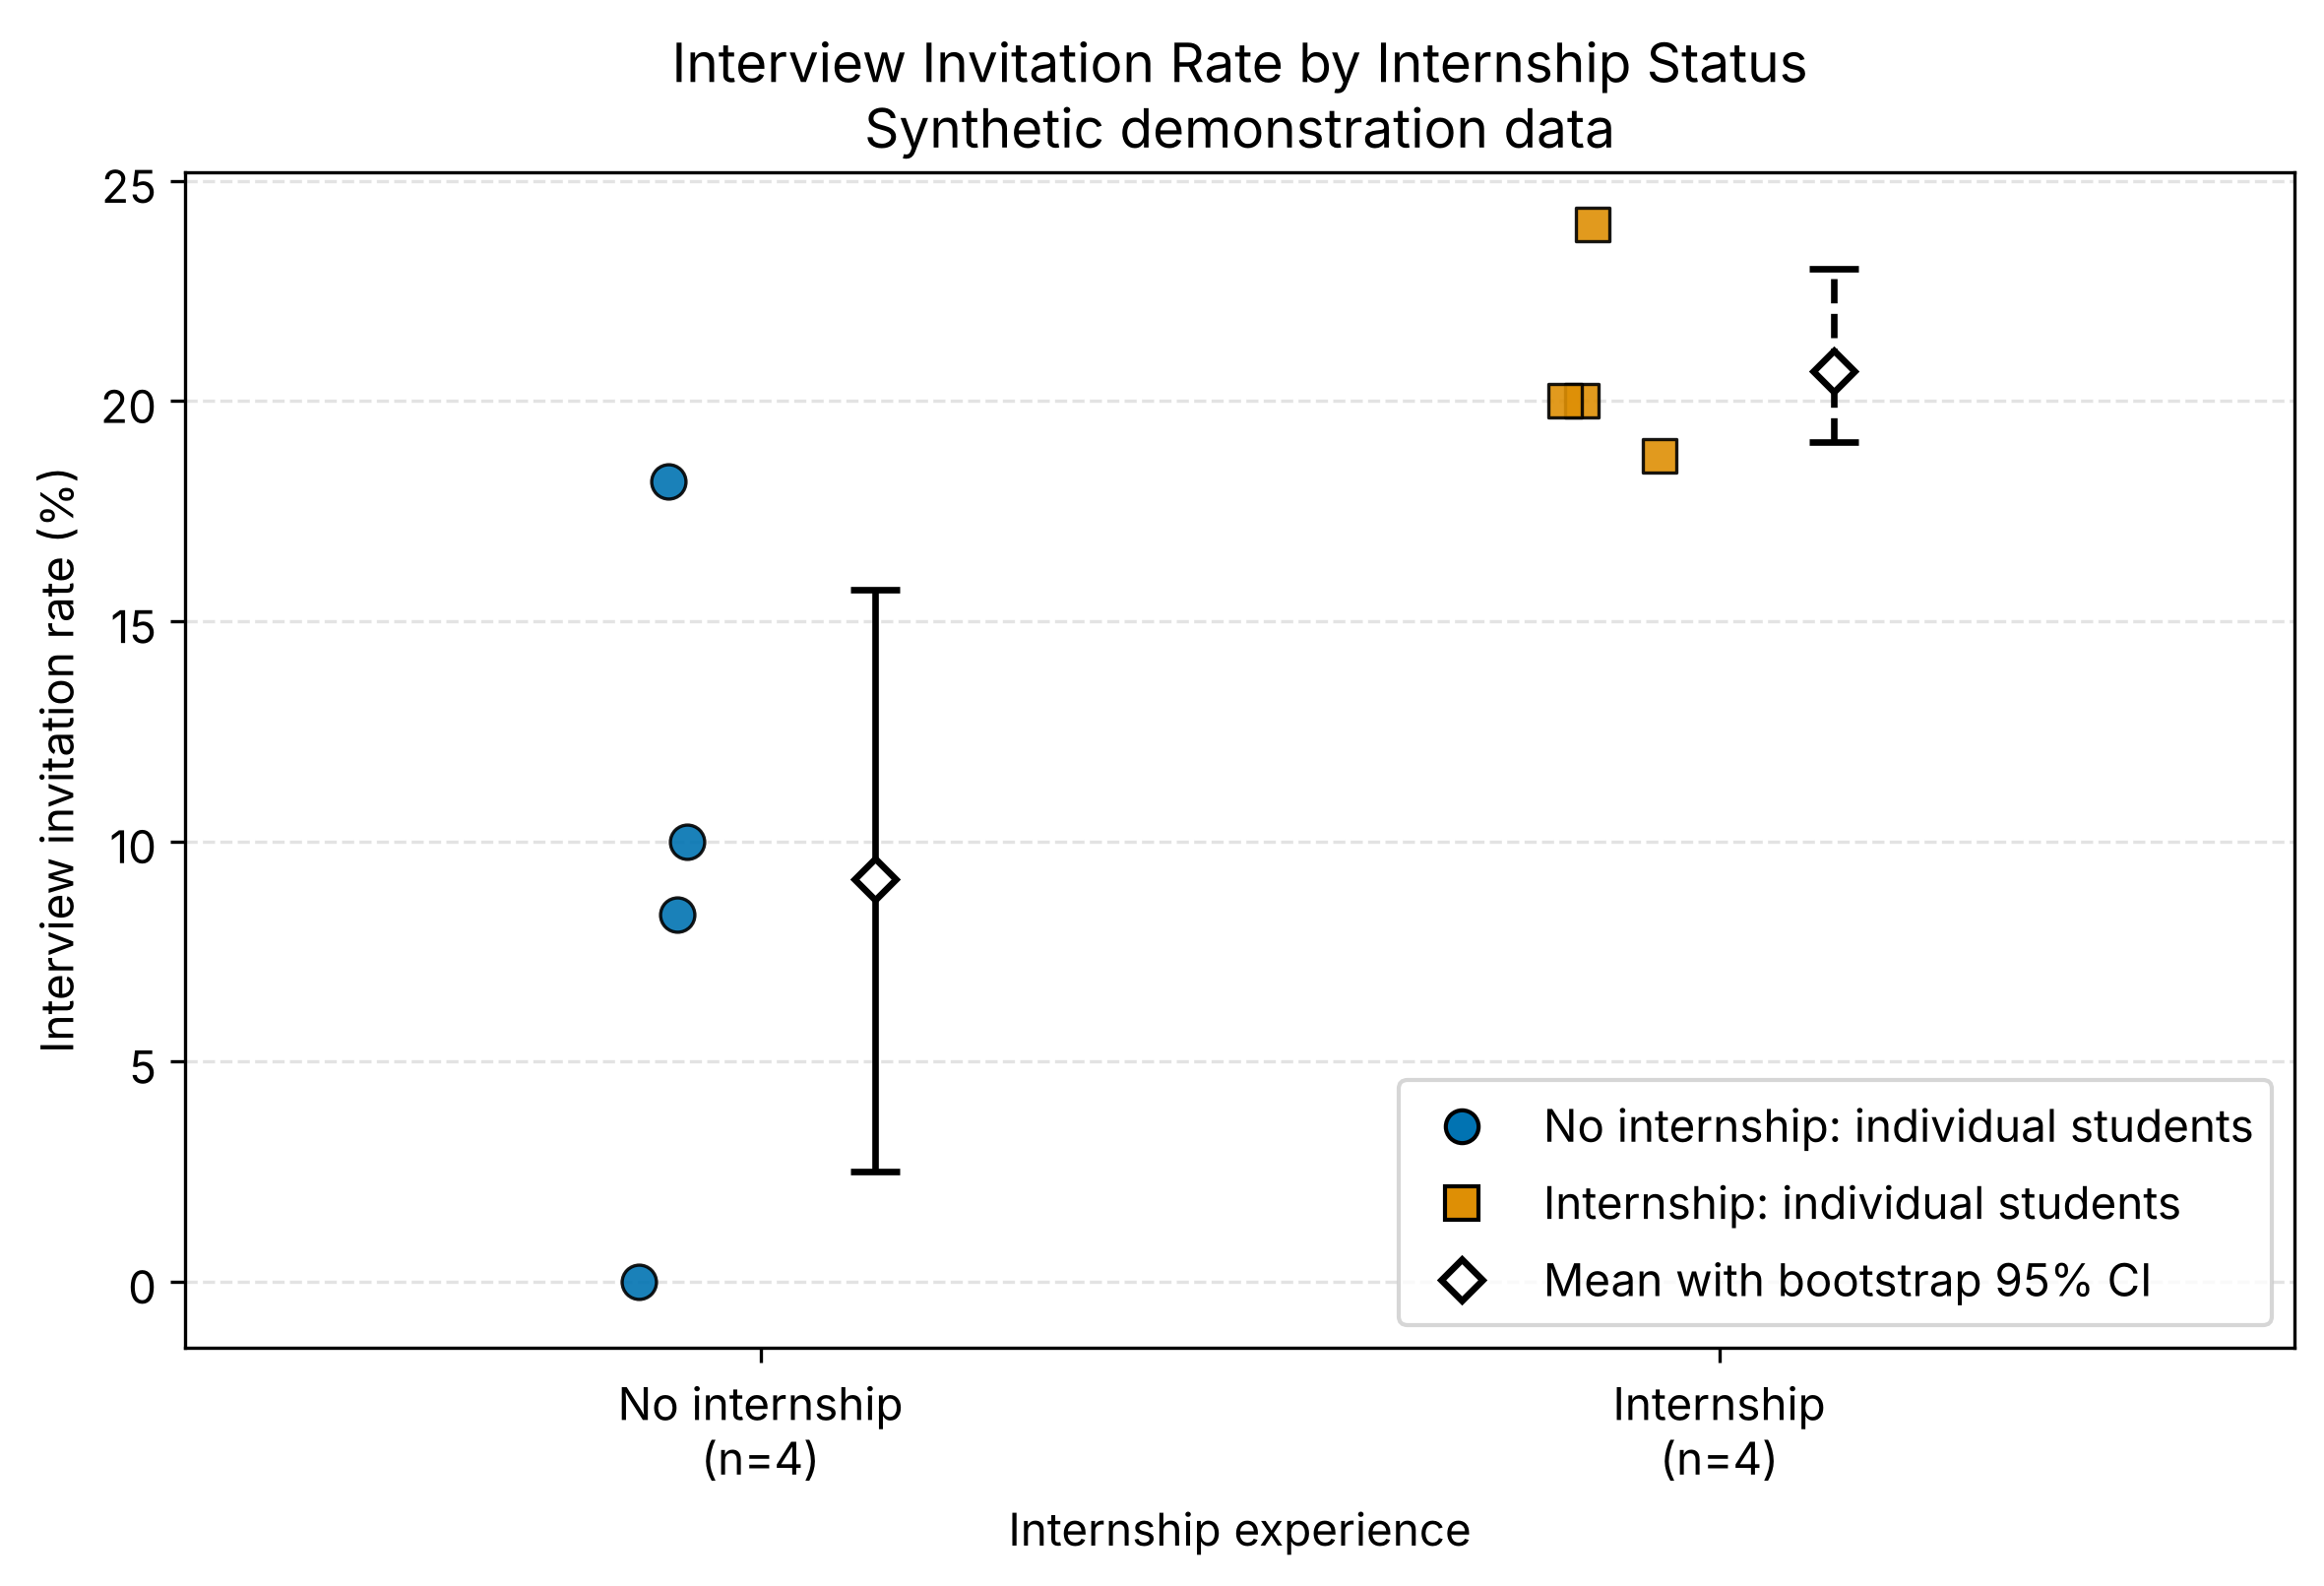

In [6]:
visualize.plot_internship_comparison(df)
display(Image(filename=str(visualize.FIGURES_DIR / "fig1_internship_comparison.png"), width=600))

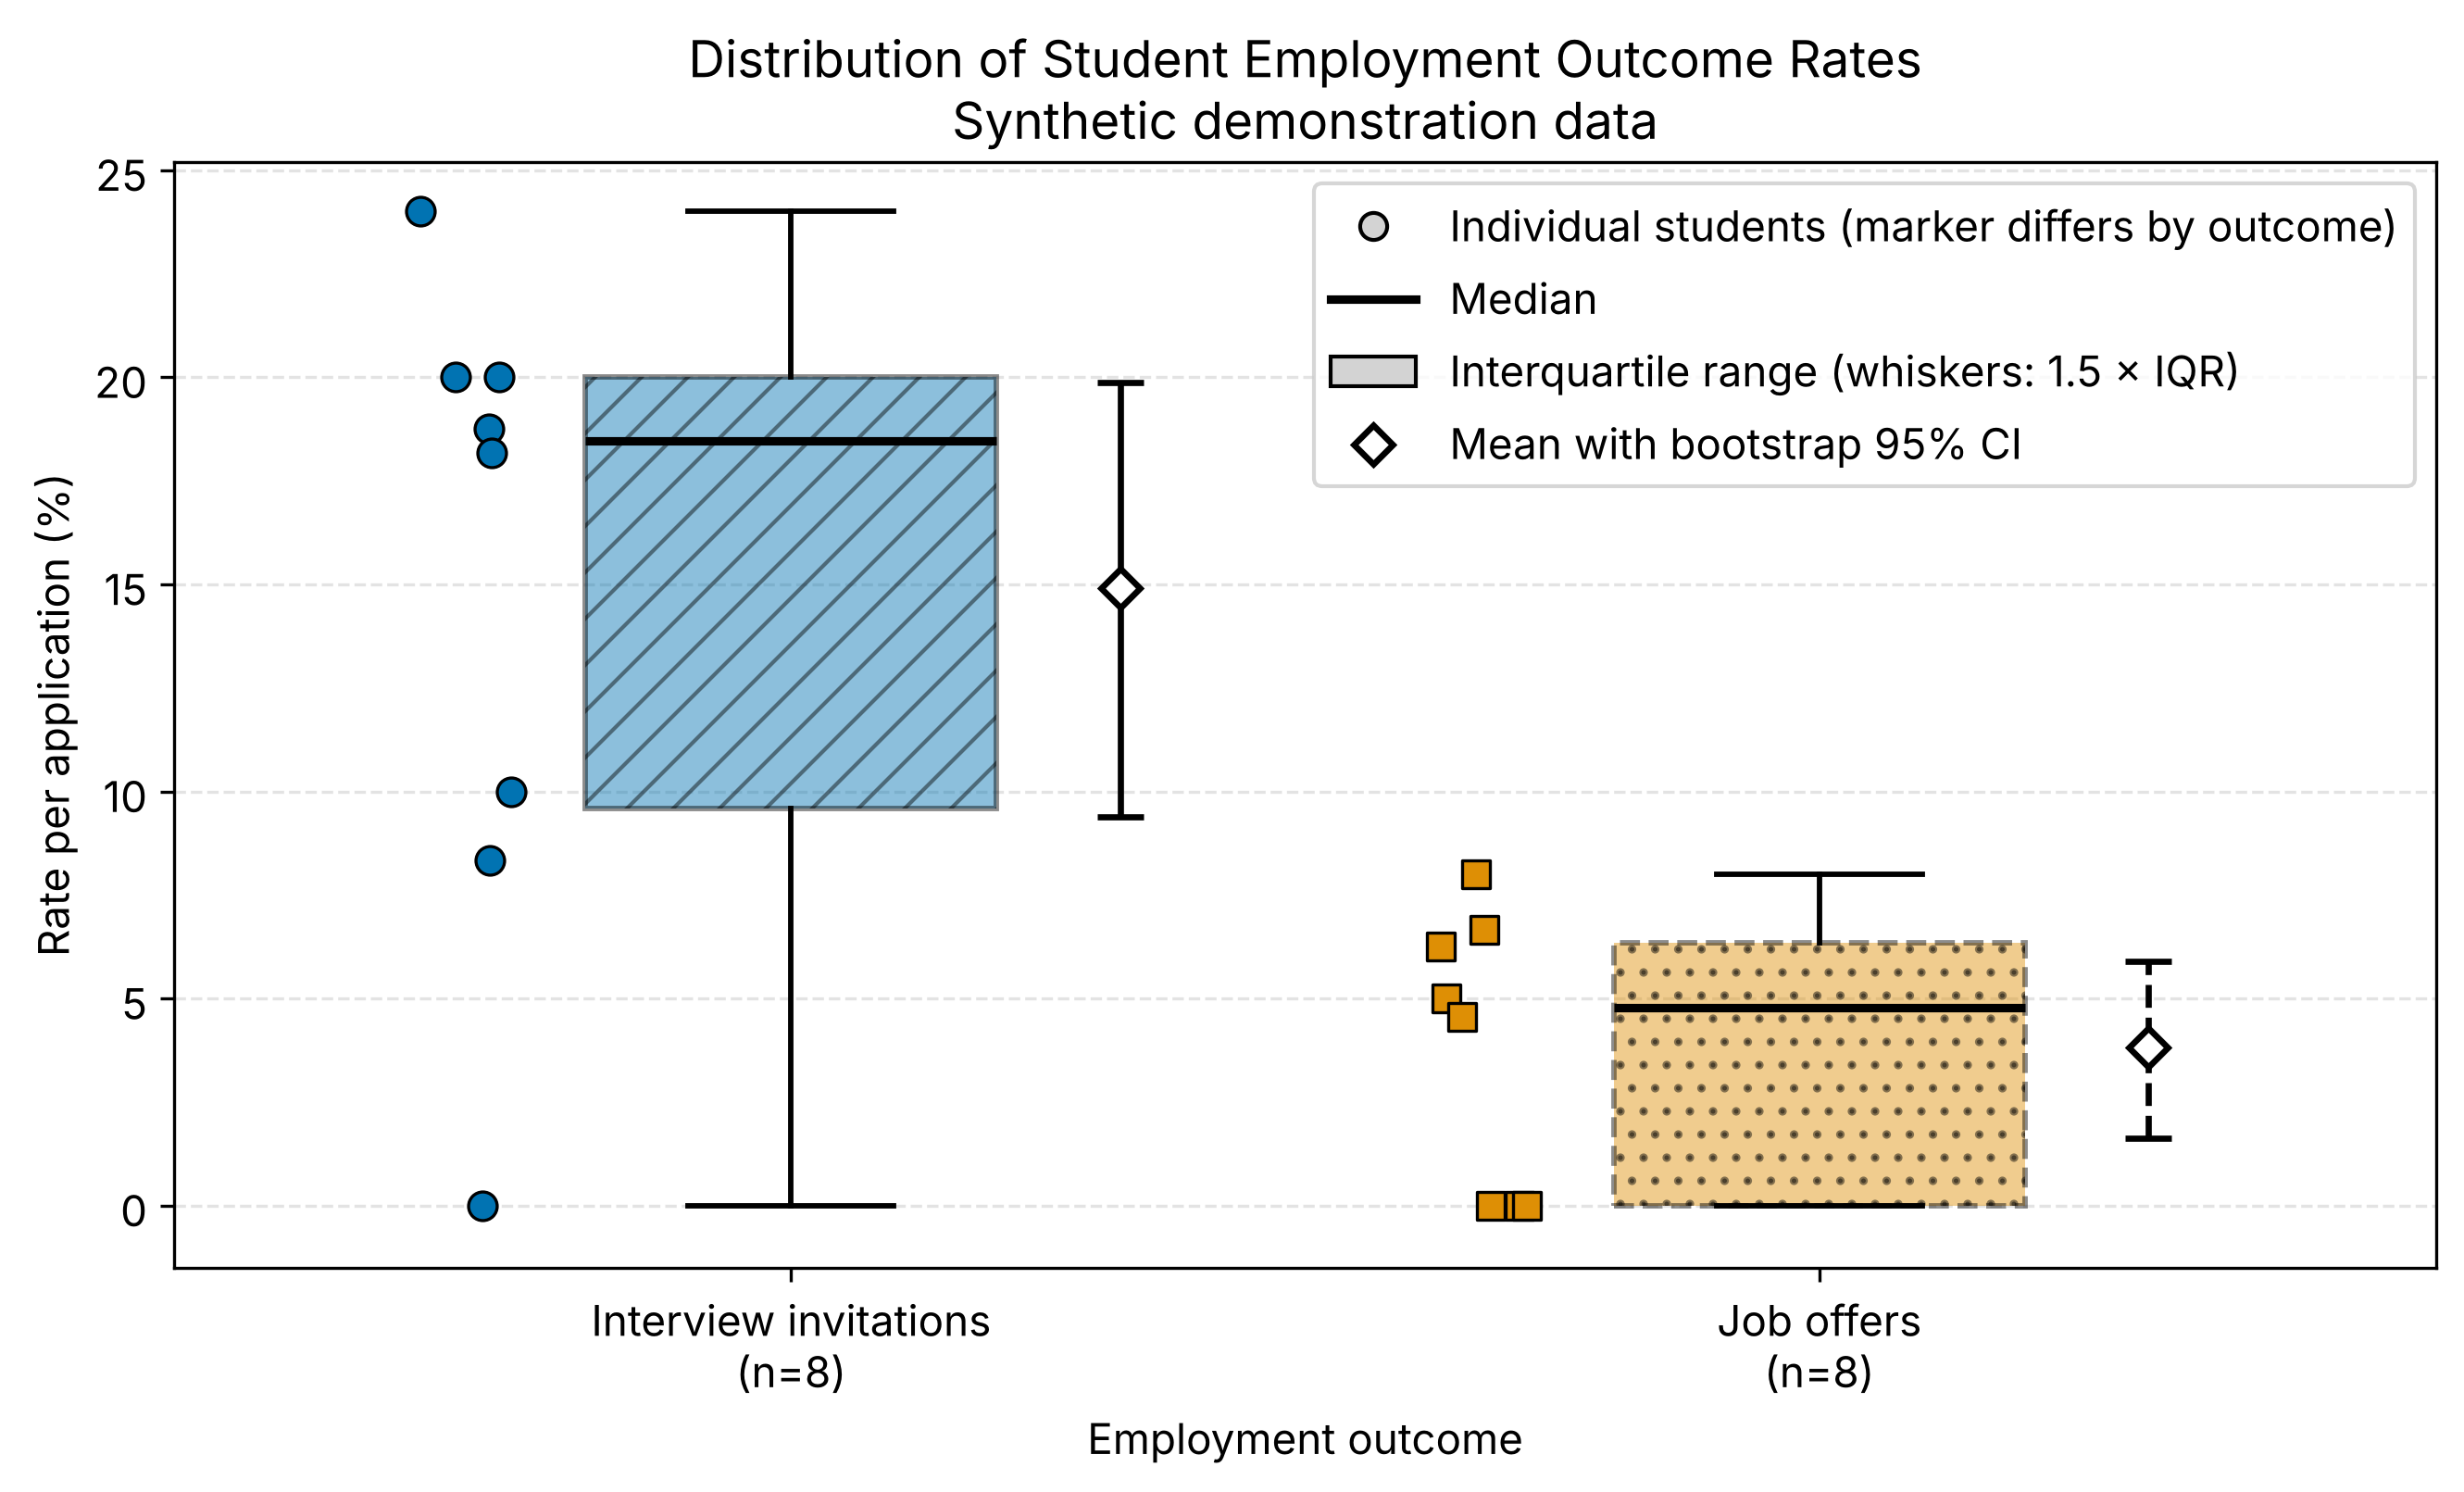

In [7]:
visualize.plot_rate_distributions(df)
display(Image(filename=str(visualize.FIGURES_DIR / "fig2_rate_distributions.png"), width=650))

## 5. Save results

The summaries are written with the same functions and column layout as the `src/statistical_analysis.py` script, so running either one produces identical files.

In [8]:
results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

stats_df.to_csv(statistical_analysis.SUMMARY_FILE, index=False)
quality.to_csv(statistical_analysis.QUALITY_FILE, index=False)

for path in [statistical_analysis.SUMMARY_FILE, statistical_analysis.QUALITY_FILE]:
    print("Saved:", path.relative_to(PROJECT_ROOT))
for name in ["fig1_internship_comparison", "fig2_rate_distributions"]:
    for ext in ("png", "pdf"):
        path = visualize.FIGURES_DIR / f"{name}.{ext}"
        print("Exists:", path.relative_to(PROJECT_ROOT), path.exists())

Saved: results/statistical_summary.csv
Saved: results/data_quality_summary.csv
Exists: reports/figures/fig1_internship_comparison.png True
Exists: reports/figures/fig1_internship_comparison.pdf True
Exists: reports/figures/fig2_rate_distributions.png True
Exists: reports/figures/fig2_rate_distributions.pdf True


## 6. Interpretation and limitations

- The pipeline runs end to end: validation, descriptive statistics, bootstrap confidence intervals, guardrail checks and figure export.
- Students with internship experience show higher rates in this sample, but with four students per group the intervals are wide and the comparison is exploratory only.
- The data are synthetic and the sample is tiny, so **no conclusion about H1, H2 or H3 can be drawn**. Testing them requires real, appropriately collected student data and a suitable statistical analysis.